# 1장 2강: 이미지 데이터셋 구성과 전처리

## 실습 목표
- 실제 동물 이미지에 크기 조정과 정규화를 적용하고, 각 단계의 입력 형태와 값 범위를 해석한다.
- 같은 원본의 증강본이 다른 세트에 섞인 상황을 진단하고, 원본 이미지 목록을 Train·Validation·Test로 구분하고, 이미지 ID와 경로의 중복 여부 및 클래스 분포를 확인한다.
- Train에는 적절한 무작위 증강을, Validation·Test에는 일정한 전처리를 적용한다.
- 라벨 보존, 데이터 누수, 모델 입력 조건의 관점에서 처리 결과와 한계를 설명한다.

## 실습 환경 / 데이터
- Python 3.10 이상, Jupyter Notebook 또는 Google Colab. CPU로 수행할 수 있다.
- 라이브러리: NumPy, pandas, Pillow, PyTorch, torchvision, scikit-learn.
- 데이터: 1장 1강과 같은 `oxford_dataset.zip`.
- 형식: **필수 1 → 필수 2 → 과제 1(필수 수준) → 실습 마무리**.
- 이번 교안의 범위는 모델 학습 전 데이터 구성과 전처리이다. CNN 구성·학습·예측·정확도 계산은 포함하지 않는다.

### 이번 데이터의 실제 구성과 사용 기준
첨부 ZIP에는 `metadata.csv`가 있으며, 원본 이미지 경로는 `images/val/품종폴더/파일명.jpg`, `images/test/품종폴더/파일명.jpg` 형태이다. 메타데이터 7,349행 중 실제 파일이 있는 이미지는 **4,405장(기존 Validation 736장, 공식 Test 3,669장)**이다. 기존 Train 2,944행의 이미지 파일은 이 ZIP에 없다.

따라서 **실제 파일이 존재하는 기존 Validation 736장을 이번 수업의 개발용 데이터로 사용하여 약 80:20으로 Train·Validation을 새로 나누고, 공식 Test 3,669장은 유지**한다. 원본 ZIP이나 CSV는 변경하지 않는다. 이 실습의 분할 비율은 전체 4,405장의 80:20이 아니며, 공식 분할의 재현 실험도 아니다.

`image_id`는 **원본 이미지 식별자**이고 `class_name`은 **품종 이름**이다. 어느 것도 동물 개체 ID가 아니다. 교안의 `GroupShuffleSplit`을 이미지 ID 기준으로 적용하지만 이것을 '동일 동물 개체의 누수 방지 완료'라고 해석하면 안 된다. 이 데이터에는 동물 개체를 식별하는 열이 제공되지 않는다.

## 실습 준비
1. ZIP을 노트북과 같은 폴더에 놓거나 `DATA_SOURCE`를 실제 ZIP 경로로 수정한다. 압축을 푼 폴더를 지정해도 된다.
2. Windows 경로 예: `Path(r"C:\data\oxford_dataset.zip")`. Colab 경로 예: `Path("/content/oxford_dataset.zip")`.
3. 준비 코드는 그대로 실행한다. ZIP 읽기·파일 존재 확인·화면 표시 함수는 실습을 위한 제공 코드이며 평가 대상이 아니다.
4. `torch.manual_seed(42)`는 증강 결과를 재현하기 위한 보조 설정이다. 무작위 증강은 실행 환경이나 셀 실행 순서에 따라 다른 결과가 나올 수 있다.
5. 필요한 라이브러리가 없다면 현재 노트북에서 `%pip install numpy pandas pillow torch torchvision scikit-learn`을 실행하고 커널을 재시작한다.

독립 과제에서는 세트별 12장, 총 36장에 변환을 실행합니다. 경로와 원본 ID가 서로 다른 질문에 답하는지, 평가 입력이 반복 실행에서 그대로인지 실제 값으로 확인합니다.

In [12]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display
import torch
import torchvision
from torchvision import transforms
from sklearn.model_selection import GroupShuffleSplit

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)

PyTorch: 2.15.0+cpu
torchvision: 0.29.2+cpu


In [13]:
choices = [Path("oxford_dataset(1).zip"), Path("oxford_dataset.zip"), Path("oxford_dataset")]
DATA_SOURCE = next((p for p in choices if p.exists()), choices[0])

# 제공 코드: 실제로 존재하는 이미지 경로만 사용합니다.
if not DATA_SOURCE.exists():
    raise FileNotFoundError("DATA_SOURCE를 실제 ZIP 또는 압축 해제 폴더 경로로 수정하세요.")

if DATA_SOURCE.is_file():
    with ZipFile(DATA_SOURCE) as zf:
        member_names = set(zf.namelist())
        metadata_paths = sorted(n for n in member_names
                                if PurePosixPath(n).name == "metadata.csv"
                                and "__MACOSX" not in n)
        if len(metadata_paths) != 1:
            raise ValueError("metadata.csv가 하나 포함된 데이터 ZIP을 지정하세요.")
        metadata_path = metadata_paths[0]
        prefix = str(PurePosixPath(metadata_path).parent)
        prefix = "" if prefix == "." else prefix + "/"
        metadata = pd.read_csv(BytesIO(zf.read(metadata_path)))
    def has_image(relative_path):
        return prefix + str(relative_path).replace("\\", "/") in member_names
    def load_rgb(relative_path):
        with ZipFile(DATA_SOURCE) as zf:
            raw = zf.read(prefix + str(relative_path).replace("\\", "/"))
        with Image.open(BytesIO(raw)) as im:
            return im.convert("RGB")
else:
    metadata_paths = sorted(DATA_SOURCE.rglob("metadata.csv"))
    if len(metadata_paths) != 1:
        raise ValueError("metadata.csv가 하나 포함된 데이터 폴더를 지정하세요.")
    data_root = metadata_paths[0].parent
    metadata = pd.read_csv(metadata_paths[0])
    def has_image(relative_path):
        return (data_root / str(relative_path)).is_file()
    def load_rgb(relative_path):
        with Image.open(data_root / str(relative_path)) as im:
            return im.convert("RGB")

required = {"image_id", "image_path", "class_name", "split"}
if not required.issubset(metadata.columns):
    raise ValueError("필수 열이 없습니다: " + str(required - set(metadata.columns)))

available = metadata[metadata["image_path"].map(has_image)].copy()
available = available.sort_values("image_path").reset_index(drop=True)
if available["image_id"].duplicated().any() or available["image_path"].duplicated().any():
    raise ValueError("이미지 ID 또는 경로가 중복됩니다. 원본 목록을 확인하세요.")

# 공식 Test를 유지하고, 실제 존재하는 기존 Validation을 이번 실습의 개발용으로 사용합니다.
pool_df = available[available["split"] == "val"].copy().reset_index(drop=True)
official_test_df = available[available["split"] == "test"].copy().reset_index(drop=True)
if len(pool_df) == 0 or len(official_test_df) == 0:
    raise ValueError("실습용 val 이미지와 공식 test 이미지가 모두 필요합니다.")

sample_row = pool_df.iloc[0]
image = load_rgb(sample_row["image_path"])
print("메타데이터 행 수:", len(metadata))
print("실제 파일이 있는 행 수:", len(available))
print("파일이 없어 제외한 행 수:", len(metadata) - len(available))
print("개발용 원본:", len(pool_df), "/ 유지할 공식 Test:", len(official_test_df))
print("개발용 품종 수:", pool_df["class_name"].nunique())
print("필수 1 이미지:", sample_row["image_path"])
print("품종:", sample_row["class_name"], "/ RGB 크기:", image.size)

# 제공 코드: 정규화한 텐서를 화면 확인용 이미지로 되돌립니다.
# (x - 0.5) / 0.5 를 되돌리므로 x * 0.5 + 0.5 를 사용합니다.
# 모델에 넣을 텐서는 변경하지 않고 표시용 복사본만 만듭니다.
def show_normalized(x, title):
    print(title)
    pixels = x.detach().cpu().permute(1, 2, 0).numpy()
    pixels = np.clip(pixels * 0.5 + 0.5, 0, 1)
    display(Image.fromarray(np.rint(pixels * 255).astype(np.uint8)))

# 세트마다 정렬된 목록에서 일정한 간격으로 12장을 고릅니다.
def sample_rows(frame, n=12):
    ordered = frame.sort_values("image_path").reset_index(drop=True)
    positions = np.linspace(0, len(ordered) - 1, n, dtype=int)
    return ordered.iloc[positions].reset_index(drop=True)

메타데이터 행 수: 7349
실제 파일이 있는 행 수: 4405
파일이 없어 제외한 행 수: 2944
개발용 원본: 736 / 유지할 공식 Test: 3669
개발용 품종 수: 37
필수 1 이미지: images/val/00_Abyssinian/Abyssinian_1.jpg
품종: Abyssinian / RGB 크기: (600, 400)


## 필수 1. 실제 이미지의 크기 조정과 정규화

**배경**  
서로 다른 크기의 동물 이미지를 모델의 공통 입력 형태로 준비하려고 합니다. 실습 준비에서 제공한 `image`를 사용하세요. 이번 단계에서는 무작위 증강 없이 기본 전처리만 확인합니다.

**요구사항**
1. **1-1:** 원본을 출력하고 `transforms.Resize((224, 224))`로 크기를 변경하세요. 원본과 변환 후 사진을 출력하세요. 같은 원본을 비율 유지·검은 여백 추가 방식으로도 224×224로 만드세요. 가로·세로 방향의 직접 축소 비율, 여백 안쪽 사진 크기와 위·아래 여백을 계산해 두 결과 중 형태와 전체 장면을 함께 보존하는 방법을 고르세요.
2. **1-2:** 크기를 변경한 이미지에 `ToTensor()`를 적용하세요. 이어서 `Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])`를 적용하세요. 두 단계의 shape·dtype·픽셀 최솟값·최댓값을 출력하세요.
3. **1-3:** 텐서의 첫 채널·첫 행·첫 열 값을 정규화 전후로 출력하고, 교안의 `(픽셀 값 - 평균) / 표준편차` 식으로 직접 계산한 값과 비교하세요. 0·0.5·1이 정규화 후 어떤 값이 되는지 적으세요.
4. **1-4:** ① Resize·정규화의 목적 차이 ② 원본을 정사각형으로 바꿀 때의 위험 ③ Crop과 Padding의 주의점 ④ 이번 평균·표준편차 0.5가 모든 모델에 적합한지 설명하세요.

**제출 결과**: 원본·크기 변경 이미지, 단계별 출력, 정규화 계산, 문항별 해석.

원본: images/val/00_Abyssinian/Abyssinian_1.jpg / 크기 (가로, 세로): (600, 400)


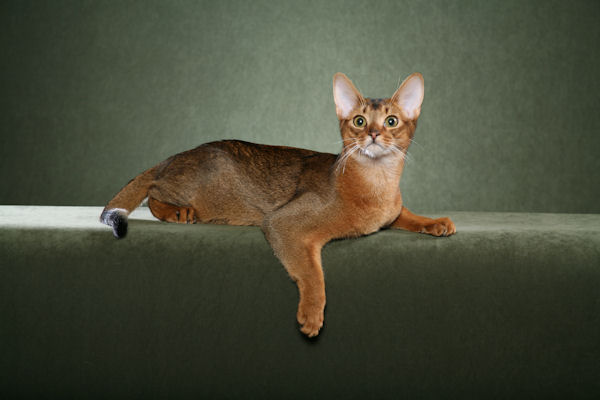

직접 Resize 결과 크기: (224, 224)


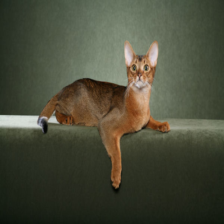

가로 축소 비율 = 224/600 = 0.3733
세로 축소 비율 = 224/400 = 0.5600
두 비율의 차이(세로/가로) = 1.5000배 → 가로·세로 비율이 달라 형태가 왜곡됨

비율 유지 축소 비율 = min(0.3733, 0.5600) = 0.3733
여백 안쪽 사진 크기 (가로, 세로): (224, 149)
위 여백 = 38px, 아래 여백 = 37px, 왼쪽 = 0px, 오른쪽 = 0px
패딩 결과 크기: (224, 224)


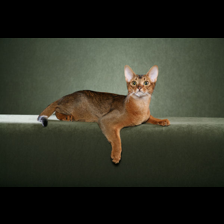

실제로 전부 0인 위쪽 행 수: 38 / 아래쪽 행 수: 37


In [14]:
# 1-1. 직접 Resize vs 비율 유지 + 검은 여백(Padding)
TARGET = 224
orig_w, orig_h = image.size
print("원본:", sample_row["image_path"], "/ 크기 (가로, 세로):", image.size)
display(image)

# (1) 직접 Resize: 가로·세로를 각각 224로 강제
resize_224 = transforms.Resize((TARGET, TARGET))
resized = resize_224(image)
print("직접 Resize 결과 크기:", resized.size)
display(resized)

scale_w = TARGET / orig_w
scale_h = TARGET / orig_h
print(f"가로 축소 비율 = 224/{orig_w} = {scale_w:.4f}")
print(f"세로 축소 비율 = 224/{orig_h} = {scale_h:.4f}")
print(f"두 비율의 차이(세로/가로) = {scale_h / scale_w:.4f}배 → 가로·세로 비율이 달라 형태가 왜곡됨")

# (2) 비율 유지 + 검은 여백
contained = ImageOps.contain(image, (TARGET, TARGET))            # 비율 유지, 224×224 안에 맞춤
padded = ImageOps.pad(image, (TARGET, TARGET), color=(0, 0, 0))  # 중앙 배치 + 검은 여백
inner_w, inner_h = contained.size
scale_keep = min(scale_w, scale_h)
# ImageOps.pad는 남는 공간 × 0.5를 반올림한 값만큼 위(왼쪽)에 여백을 둡니다.
top = round((TARGET - inner_h) * 0.5)
bottom = TARGET - inner_h - top
left = round((TARGET - inner_w) * 0.5)
right = TARGET - inner_w - left
print(f"\n비율 유지 축소 비율 = min({scale_w:.4f}, {scale_h:.4f}) = {scale_keep:.4f}")
print("여백 안쪽 사진 크기 (가로, 세로):", contained.size)
print(f"위 여백 = {top}px, 아래 여백 = {bottom}px, 왼쪽 = {left}px, 오른쪽 = {right}px")
print("패딩 결과 크기:", padded.size)
display(padded)

# 실제 배열에서 여백 행이 모두 검은색(0)인지 확인
padded_arr = np.array(padded)
black_rows = (padded_arr.max(axis=(1, 2)) == 0)
print("실제로 전부 0인 위쪽 행 수:", int(black_rows[:TARGET // 2].sum()),
      "/ 아래쪽 행 수:", int(black_rows[TARGET // 2:].sum()))

### 1-1. 정사각형 입력 두 개가 고양이를 다르게 보여주는 이유
### 원본 Abyssinian_1.jpg는 가로 600 x 세로 400입니다. 직접 Resize한 사진과 여백을 더한 사진은 모두 224 x 224이다. 고양이의 몸 비율과 사진 가장자리까지 함께 보존하는 조건에서는 여백을 추가한 결과를 선택한다.
|출력 순서|코드가 실제로 한 일|사진에서 확인할 부분|
|---|---|---|
|첫 번째 그림|image.size로 원본 가로, 세로를 읽고 display()|고양이가 가로로 긴 받침 위에 있고 몸ㅌ통의 가로 길이와 아래로 내려온 다리를 기준으로 삼는다.|
|두 번째 그림|Resizw((224, 224))가 가로와 세로를 지정한 크기로 각각 바꿈|같은 고양이가 상대적으로 가늘고 길어보이게 매치됨, 원본 장면은 화면에 들어 있지만 두 방향의 축소 비율이 다르다.|
|세 번째 그림|ImageOps.contain으로 비율을 유지했을 때의 크기를 구하고, Imageops.pad로 검은 바탕 한 가운데 배치|실제 사진은 가운데 가로 띠에 놓입니다. 받침과 고양이 몸의 원래 비율을 확인할 수 있다.|

### 계산식 이해하기
### 가로는 224 / 600 = 약 0.37배, 세로는 224 / 400 = 약 0.56배, 가로가 더 많이 줄었기 때문에 Resize에서 형태가 변한다.
### 이 비율을 유지하기 위해서는 두 축에 같은 약 0.37을 적용해야 한다. 세로는 400 x 0.37 = 149픽셀
### 실제 출력 사진 영역은 224 x 149, 남은 높이는 224 - 149로 75픽셀을 의미한다.

In [15]:
# 1-2. ToTensor → Normalize(mean=0.5, std=0.5)
to_tensor = transforms.ToTensor()
normalize = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

resized_arr = np.array(resized)
x_tensor = to_tensor(resized)
x_norm = normalize(x_tensor)

def describe(name, obj):
    if isinstance(obj, np.ndarray):
        print(f"{name:<22} shape={obj.shape}, dtype={obj.dtype}, min={obj.min()}, max={obj.max()}")
    else:
        print(f"{name:<22} shape={tuple(obj.shape)}, dtype={obj.dtype}, "
              f"min={obj.min().item():.4f}, max={obj.max().item():.4f}")

describe("Resize 후 (PIL→배열)", resized_arr)
describe("ToTensor 후", x_tensor)
describe("Normalize 후", x_norm)

Resize 후 (PIL→배열)      shape=(224, 224, 3), dtype=uint8, min=1, max=236
ToTensor 후             shape=(3, 224, 224), dtype=torch.float32, min=0.0039, max=0.9255
Normalize 후            shape=(3, 224, 224), dtype=torch.float32, min=-0.9922, max=0.8510


### 1-2. 0 ~ 1 변환과 평균, 표준편차 정규화를 단계별로 읽기
### 두 텐서 모두 (3, 224, 224)의 torch.float32입니다. 한 장에서 실제 관측된 최솟값, 최댓값은 ToTensor 후 약 0.003922와 0.925490, Normalize 후 약 - 0.992157과 0.850980입니다.
### 1. transforms.ToTensor()(resized)에서 앞 괄호는 변환을 준비하고, 뒤 괄호는 그 변환을 실제 PIL 사진에 적용한다. 이번 8비트 RGB 입력에서는 픽셀 성분을 255로 나눠 실수로 바꾸고 축을(채널, 높이, 너비)로 놓는다.
### 2. Normalize(mean=[0.5, 0.5, 0.5], std = [0.5, 0.5, 0.5])는 R,G,B 각각에서 뺄 값과 나눌 값을 지정한다. 사진 한 장의 평균과 표준편차를 이 줄에서 계산한 것은 아니다.
### 3. tensor_norm = normalizer(tensor_01)에서 수치가 바뀐다. 직사각형의 위치나 채널 수는 바뀌지 않으므로 shape도 그대로이다. 반복문 전 / 후 텐서에서 같은 항목으로 출력하므로 값을 바로 비교할 수 있다.
### 4. x.min().item()은 세 채널의 모든 위치를 살펴 가장 작은 수 하나를 꺼낸다. 점 하나의 빨강 값을 읽는 다음 문항과 구분한다.
### 왜 최솟값이 정확히 -1이 아닌가? -> 직접 Resize한 사진에서 가장 어두운 채널 값은 1 / 255 약 0.003922이고, 가장 큰 값은 26 / 255로 약 0.92이다. 이번 설정에서 정규화 식은 (x - 0.5 ) / 0.5 = 2x-1이고 두 값을 대입하면 각각 -0.99와 0.85가 된다. -1 ~ 1은 가능함 범위이고 -1과1을 반드시 포함해야하는 것은 아니다.

In [16]:
# 1-3. 첫 채널·첫 행·첫 열 값의 정규화 전후 비교
mean, std = 0.5, 0.5
raw_value = int(resized_arr[0, 0, 0])          # Resize 후 R 채널 (0,0)의 0~255 값
before = x_tensor[0, 0, 0].item()              # ToTensor 후 값 (0~1)
after = x_norm[0, 0, 0].item()                 # Normalize 후 값
manual = (before - mean) / std                 # 교안 식으로 직접 계산

print(f"Resize 후 원래 픽셀 값(0~255): {raw_value}")
print(f"ToTensor 후: {raw_value}/255 = {before:.6f}")
print(f"Normalize 후 (torchvision): {after:.6f}")
print(f"직접 계산 ({before:.6f} - {mean}) / {std} = {manual:.6f}")
print("두 값이 같은가?", np.isclose(after, manual))

print("\n대표 값의 정규화 결과")
for v in [0.0, 0.5, 1.0]:
    print(f"  {v:.1f} → ({v} - {mean}) / {std} = {(v - mean) / std:+.1f}")

Resize 후 원래 픽셀 값(0~255): 30
ToTensor 후: 30/255 = 0.117647
Normalize 후 (torchvision): -0.764706
직접 계산 (0.117647 - 0.5) / 0.5 = -0.764706
두 값이 같은가? True

대표 값의 정규화 결과
  0.0 → (0.0 - 0.5) / 0.5 = -1.0
  0.5 → (0.5 - 0.5) / 0.5 = +0.0
  1.0 → (1.0 - 0.5) / 0.5 = +1.0


### 문항별 해석 작성

**1-1 답변:** 원본(`Abyssinian_1.jpg`)은 600×400(가로×세로)입니다. `Resize((224, 224))`로 직접 바꾸면 가로는 224/600 = **0.3733배**, 세로는 224/400 = **0.5600배**로 서로 다르게 축소됩니다. 세로가 가로보다 1.5배 더 늘어난 셈이라 고양이가 위아래로 늘어나 보이는 형태 왜곡이 생깁니다. 비율 유지·검은 여백 방식은 가로·세로 모두 작은 쪽 비율(0.3733)로 축소합니다. 그래서 여백 안쪽 사진이 **224×149**가 되고, 남은 75px는 **위 38px, 아래 37px**의 검은 여백으로 채워집니다(실제 배열에서도 0인 행이 위 38개, 아래 37개). 이 방법은 장면을 잘라내지 않고 형태 비율도 지키므로 **형태와 전체 장면을 함께 보존하는 방법은 비율 유지 + 여백(Padding)** 입니다. 대신 입력의 약 33%(75/224)가 정보가 없는 검은 영역이 됩니다.

**1-2 답변:** Resize 후 PIL 이미지를 배열로 보면 `(224, 224, 3)`, `uint8`, 값 범위 1~236입니다. `ToTensor()`를 적용하면 `(3, 224, 224)`, `float32`가 되어 축 순서가 CHW로 바뀌고 값을 255로 나눠 0.0039~0.9255(0~1 범위)가 됩니다. `Normalize(0.5, 0.5)`를 적용해도 shape와 dtype은 그대로이고 값만 -0.9922~0.8510(-1~1 범위)으로 옮겨집니다. 즉 ToTensor는 구조·자료형·스케일을, Normalize는 값의 중심과 퍼짐을 바꿉니다.

**1-3 답변:** 첫 채널(R)·첫 행·첫 열의 원래 값은 30입니다. ToTensor 후 30/255 = **0.117647**이고, Normalize 후 torchvision 결과는 **-0.764706**입니다. 교안 식으로 직접 계산한 (0.117647 − 0.5) / 0.5 = **-0.764706**과 일치합니다. 평균·표준편차가 0.5일 때 **0 → -1, 0.5 → 0, 1 → +1**이 되므로, 0~1 범위가 0을 중심으로 한 -1~1 범위로 옮겨집니다.

**1-4 답변:**
① **Resize**는 크기가 제각각인 사진을 모델이 요구하는 같은 공간 크기(224×224)로 맞춰 한 배치로 쌓을 수 있게 하는 **형태(구조) 맞춤**입니다. **정규화**는 픽셀 값의 범위·중심을 일정하게 맞춰 학습을 안정시키고, 사전학습 모델이 학습 때 본 값 분포와 맞추는 **값(스케일) 맞춤**입니다.
② 원본을 정사각형으로 바로 바꾸면 가로·세로 축소 비율이 달라(이번 0.3733 vs 0.56) 동물의 체형·얼굴 비율 같은 **형태 정보가 왜곡**됩니다. 품종처럼 형태가 중요한 분류에서는 판단 근거가 훼손될 수 있습니다.
③ **Crop**은 비율은 지키지만 가장자리를 잘라내므로 귀·꼬리 등 대상의 일부가 **잘려 나갈** 수 있습니다. 특히 대상이 중앙에 없으면 핵심 부분을 잃습니다. **Padding**은 장면을 모두 보존하지만 정보 없는 여백이 입력의 상당 부분(이번 약 33%)을 차지해 실제 대상의 해상도가 줄어듭니다. 또 여백 색(0)이 정규화 후 -1이 되어 모델이 여백을 특징으로 학습할 수도 있습니다.
④ 평균·표준편차 0.5는 값을 -1~1로 옮기는 **간단한 관례값**일 뿐 모든 모델에 맞지 않습니다. 사전학습 모델은 학습 때 사용한 값(예: ImageNet의 mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])을 그대로 써야 입력 분포가 맞습니다. 따라서 **사용하는 모델·가중치의 권장 전처리를 확인**해야 합니다.

---
## 필수 2. 원본 이미지 분할과 데이터 누수 점검

**배경**  
ZIP에 실제로 존재하는 이미지로 학습용·선택용·최종 평가용 목록을 만들려고 합니다. 준비된 `pool_df`는 개발용 원본 736장, `official_test_df`는 유지할 공식 Test 목록입니다. 이미지를 증강하거나 파일을 옮기기 전에 **원본 목록부터 분할**하세요.

**요구사항**
1. **2-1:** `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)`를 사용하여 `pool_df`를 Train·Validation으로 분할하세요. 그룹은 `image_id`로 지정하고 `iloc`로 행을 선택하세요. Test는 `official_test_df`를 사용하세요.
2. **2-2:** 각 세트의 이미지 수와 품종 수, 개발용 원본 안에서의 Train·Validation 비율을 출력하세요. 품종별 개수와 세트 내부 비율을 표로 비교하세요. Train과 Validation의 세트 내 비율 차이(퍼센트포인트)가 가장 큰 품종 한 개를 골라 두 비율과 장수를 인용하세요. 아래 제공된 집계 코드의 변수 이름을 연결해 사용해도 됩니다.
3. **2-3:** 세트 간 `image_id` 집합과 `image_path` 집합이 서로 겹치지 않는지 각각 확인하세요. 교안의 isdisjoint와 assert를 사용하세요. 다음으로 Train 첫 사진의 좌우 반전본을 메모리에서 만들고, 원본 ID는 같고 경로만 다른 행을 Validation의 점검용 사본에 추가하세요. Train과 이 사본 간에 경로 검사와 원본 ID 검사가 각각 무엇을 탐지하는지 출력하세요. 원래 세트는 보존하세요.
4. **2-4:** ① 각 세트의 역할 ② 이번 그룹의 의미 ③ 클래스 비율 유지 여부와 더 적합한 분할 개념 ④ 이미지 ID 중복 없음으로 확인할 수 없는 누수 ⑤ 증강보다 분할을 먼저 해야 하는 이유를 설명하세요.

**분포 집계용 제공 코드**
```python
count_table = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int).sort_index()
ratio_table = count_table.div(count_table.sum(axis=0), axis=1).mul(100).round(2)
display(count_table)
display(ratio_table)
```

**제출 결과**: 분할 코드, 건수·비율 표, 중복 검사 결과, 누수 점검의 범위와 한계.

In [17]:
# 2-1. 원본 목록을 image_id 그룹 기준으로 Train·Validation 분할, Test는 공식 Test 유지
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(pool_df, groups=pool_df["image_id"]))

train_df = pool_df.iloc[train_idx].reset_index(drop=True)
val_df = pool_df.iloc[val_idx].reset_index(drop=True)
test_df = official_test_df.copy()

print("Train 인덱스 수:", len(train_idx), "/ Validation 인덱스 수:", len(val_idx))
print("Train 앞 3행:")
display(train_df[["image_id", "image_path", "class_name"]].head(3))

Train 인덱스 수: 588 / Validation 인덱스 수: 148
Train 앞 3행:


,image_id,image_path,class_name
0,Abyssinian_1,images/val/00_Abyssinian/Abyssinian_1.jpg,Abyssinian
1,Abyssinian_10,images/val/00_Abyssinian/Abyssinian_10.jpg,Abyssinian
2,Abyssinian_111,images/val/00_Abyssinian/Abyssinian_111.jpg,Abyssinian


In [18]:
# 2-2. 세트별 이미지 수·품종 수·비율, 품종별 분포 비교
summary = pd.DataFrame({
    "이미지 수": [len(train_df), len(val_df), len(test_df)],
    "품종 수": [train_df["class_name"].nunique(), val_df["class_name"].nunique(),
              test_df["class_name"].nunique()],
}, index=["Train", "Validation", "Test"])
display(summary)

dev_total = len(train_df) + len(val_df)
print(f"개발용 원본 {dev_total}장 중 Train {len(train_df) / dev_total:.2%}, "
      f"Validation {len(val_df) / dev_total:.2%}")

count_table = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int).sort_index()
ratio_table = count_table.div(count_table.sum(axis=0), axis=1).mul(100).round(2)
print("\n[품종별 장수]")
display(count_table)
print("[세트 내부 비율(%)]")
display(ratio_table)

# Train과 Validation의 세트 내 비율 차이(%p)가 가장 큰 품종
gap = (ratio_table["Train"] - ratio_table["Validation"]).abs()
worst = gap.idxmax()
print(f"비율 차이가 가장 큰 품종: {worst}")
print(f"  Train {ratio_table.loc[worst, 'Train']}% ({count_table.loc[worst, 'Train']}장) vs "
      f"Validation {ratio_table.loc[worst, 'Validation']}% ({count_table.loc[worst, 'Validation']}장)"
      f" → 차이 {gap[worst]:.2f}%p")

,이미지 수,품종 수
Train,588,37
Validation,148,37
Test,3669,37


개발용 원본 736장 중 Train 79.89%, Validation 20.11%

[품종별 장수]


,Train,Validation,Test
class_name,,,
Abyssinian,18,2,98
Bengal,15,5,100
Birman,16,4,100
Bombay,9,10,88
British_Shorthair,14,6,100
Egyptian_Mau,17,2,97
Maine_Coon,16,4,100
Persian,18,2,100
Ragdoll,17,3,100


[세트 내부 비율(%)]


,Train,Validation,Test
class_name,,,
Abyssinian,3.06,1.35,2.67
Bengal,2.55,3.38,2.73
Birman,2.72,2.70,2.73
Bombay,1.53,6.76,2.40
British_Shorthair,2.38,4.05,2.73
Egyptian_Mau,2.89,1.35,2.64
Maine_Coon,2.72,2.70,2.73
Persian,3.06,1.35,2.73
Ragdoll,2.89,2.03,2.73


비율 차이가 가장 큰 품종: Bombay
  Train 1.53% (9장) vs Validation 6.76% (10장) → 차이 5.23%p


Train      vs Validation image_id 겹침 없음: True / image_path 겹침 없음: True
Train      vs Test       image_id 겹침 없음: True / image_path 겹침 없음: True
Validation vs Test       image_id 겹침 없음: True / image_path 겹침 없음: True

Train 첫 사진: images/val/00_Abyssinian/Abyssinian_1.jpg / image_id: Abyssinian_1


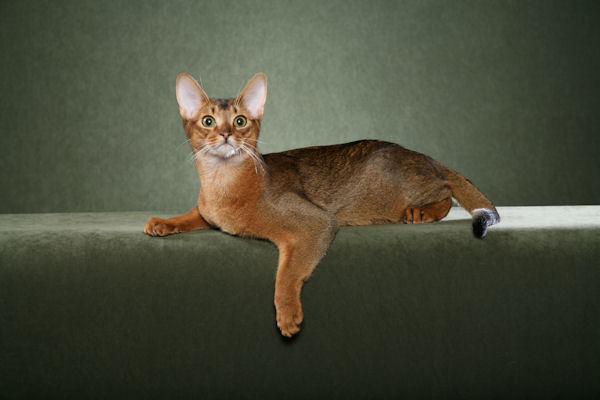

추가한 행 경로: images/val/00_Abyssinian/Abyssinian_1_hflip.jpg

[Train vs Validation 점검용 사본]
경로 검사로 탐지한 중복 수: 0 set()
원본 ID 검사로 탐지한 중복 수: 1 {'Abyssinian_1'}

원래 val_df 행 수: 148 / 점검용 사본 행 수: 149


In [19]:
# 2-3. 세트 간 image_id·image_path 중복 검사 + 증강본 누수 점검
sets = {"Train": train_df, "Validation": val_df, "Test": test_df}
pairs = [("Train", "Validation"), ("Train", "Test"), ("Validation", "Test")]

for a, b in pairs:
    ids_ok = set(sets[a]["image_id"]).isdisjoint(set(sets[b]["image_id"]))
    paths_ok = set(sets[a]["image_path"]).isdisjoint(set(sets[b]["image_path"]))
    assert ids_ok, f"{a}-{b} image_id 중복"
    assert paths_ok, f"{a}-{b} image_path 중복"
    print(f"{a:<10} vs {b:<10} image_id 겹침 없음: {ids_ok} / image_path 겹침 없음: {paths_ok}")

# Train 첫 사진의 좌우 반전본을 메모리에서 생성 (파일은 저장하지 않음)
first = train_df.iloc[0]
flipped_image = ImageOps.mirror(load_rgb(first["image_path"]))
print("\nTrain 첫 사진:", first["image_path"], "/ image_id:", first["image_id"])
display(flipped_image)

# 원본 ID는 같고 경로만 다른 행을 Validation '점검용 사본'에 추가 (val_df는 그대로)
leak_row = first.copy()
leak_row["image_path"] = str(PurePosixPath(first["image_path"]).with_name(
    PurePosixPath(first["image_path"]).stem + "_hflip.jpg"))
val_check_df = pd.concat([val_df, leak_row.to_frame().T], ignore_index=True)
print("추가한 행 경로:", leak_row["image_path"])

path_overlap = set(train_df["image_path"]) & set(val_check_df["image_path"])
id_overlap = set(train_df["image_id"]) & set(val_check_df["image_id"])
print("\n[Train vs Validation 점검용 사본]")
print("경로 검사로 탐지한 중복 수:", len(path_overlap), path_overlap)
print("원본 ID 검사로 탐지한 중복 수:", len(id_overlap), id_overlap)

print("\n원래 val_df 행 수:", len(val_df), "/ 점검용 사본 행 수:", len(val_check_df))
assert set(train_df["image_id"]).isdisjoint(val_df["image_id"]), "원래 세트가 변경됨"

### 문항별 해석 작성

**2-1 답변:** `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)`에 `groups=pool_df["image_id"]`를 지정해 개발용 원본 736장을 나눴습니다. 그 결과 **Train 588장, Validation 148장**입니다. `split()`이 돌려준 위치 인덱스를 `iloc`로 선택해 행을 만들었고, Test는 공식 Test 3,669장(`official_test_df`)을 그대로 사용했습니다. 같은 `image_id`는 반드시 같은 세트에만 들어가도록 분할했습니다. `random_state=42`로 고정했으므로 다시 실행해도 같은 분할이 나옵니다.

**2-2 답변:** 세트별 이미지 수는 Train 588 / Validation 148 / Test 3,669이고, 세 세트 모두 **37개 품종**을 포함합니다. 개발용 원본 안의 비율은 **Train 79.89% : Validation 20.11%** 로 목표 80:20에 가깝습니다. 그러나 품종별 세트 내 비율은 고르지 않습니다. Train과 Validation의 차이가 가장 큰 품종은 **Bombay**로, **Train 1.53%(9장) vs Validation 6.76%(10장)**, 차이 **5.23%p**입니다. 이 밖에 Russian_Blue·leonberger는 Validation에 1장(0.68%)만 들어갔습니다. 이는 GroupShuffleSplit이 그룹 단위로만 무작위로 나누고 **클래스 비율은 고려하지 않기** 때문입니다.

**2-3 답변:** 세 쌍(Train–Validation, Train–Test, Validation–Test) 모두 `isdisjoint`로 `image_id`와 `image_path`가 **겹치지 않음(True)** 을 확인했고 `assert`도 통과했습니다. 다음으로 Train 첫 사진(`Abyssinian_1`)의 좌우 반전본을 메모리에서 만들었습니다. 원본 ID는 같고 경로만 `..._hflip.jpg`로 다른 행을 Validation **점검용 사본**에 추가했습니다(원래 `val_df` 148행은 그대로, 사본만 149행). 이 상태에서 **경로 검사는 중복 0건으로 누수를 탐지하지 못했고**, **원본 ID 검사는 `Abyssinian_1` 1건을 탐지**했습니다. 즉 증강본은 새 파일 경로를 가지므로 경로 비교만으로는 같은 원본에서 나온 사진을 찾을 수 없고, 원본 ID 단위로 검사해야 합니다.

**2-4 답변:**
① **Train**은 모델 가중치를 학습하는 데, **Validation**은 하이퍼파라미터·전처리·모델을 고르는 데 사용합니다. **Test**는 모든 선택이 끝난 뒤 한 번만 최종 성능을 평가하는 데 사용하며, 선택 과정에 쓰면 안 됩니다.
② 이번 그룹은 `image_id`, 즉 **원본 이미지 단위**입니다. 같은 원본(과 그 증강본)이 서로 다른 세트에 흩어지지 않게 하는 의미이며, **동물 개체 단위 그룹이 아닙니다**. 현재 image_id가 모두 달라 그룹 하나에 사진 한 장이므로 일반 무작위 분할과 효과가 같습니다.
③ 클래스 비율은 **유지되지 않았습니다**(Bombay 1.53% vs 6.76%, 최대 5.23%p 차이). 품종 비율까지 맞추려면 **층화 분할(Stratified split)** 이 더 적합합니다. 그룹도 함께 지켜야 하면 `StratifiedGroupKFold` 같은 **층화 + 그룹 분할**을 사용합니다.
④ image_id 중복이 없어도 **같은 동물 개체를 다른 날/각도로 찍은 서로 다른 사진**, 연속 촬영한 거의 같은 사진, 다른 파일명으로 저장된 동일·유사 이미지는 확인할 수 없습니다. 이 데이터에는 개체 ID가 없으므로 이런 누수는 이번 검사의 범위 밖입니다.
⑤ 증강을 먼저 하면 한 원본에서 나온 반전·색 변형본들이 Train과 Validation/Test에 나뉘어 들어갈 수 있습니다. 그러면 모델이 사실상 본 사진으로 평가받아 성능이 부풀려집니다(2-3에서 경로 검사로는 이를 탐지하지 못함). 따라서 **원본 목록을 먼저 분할**하고, 증강은 분할 후 **Train에만** 적용해야 합니다.

---
## 과제 1. 학습용·평가용 전처리 파이프라인 구성 — 필수 수준

**배경**  
동물의 품종을 분류하기 위한 입력 데이터를 준비합니다. 촬영 방향과 조명의 차이를 학습 데이터에 반영하되 평가 입력은 일정하게 유지하려고 합니다. **실습 준비 셀만 실행한 상태에서도 수행할 수 있도록**, `pool_df`, `official_test_df`, `load_rgb`, `show_normalized`에서 시작하세요. 필수 문제의 정답 변수는 사용하지 않습니다.

**요구사항**
1. **3-1:** 필수 2와 같은 설정의 `GroupShuffleSplit`으로 `pool_df`를 다시 분할하여 `task_train_df`, `task_val_df`를 만드세요. `Compose`로 아래 두 파이프라인을 구성하고 출력하세요.
   - Train: `Resize((224,224)) → RandomHorizontalFlip(p=0.5) → ColorJitter(brightness=0.2) → ToTensor → Normalize(mean=0.5 세 개, std=0.5 세 개)`
   - Validation/Test: 같은 Resize·ToTensor·Normalize만 적용
2. **3-2:** 제공 함수 sample_rows로 각 세트에서 12장을 고르세요. 실제 JPEG를 읽어 Train에는 학습용, Validation·Test에는 평가용 변환을 적용하고 세트별 배치를 만드세요. 36장 전체의 입력 조건을 확인하고, 세트별 첫 파일·품종·배치 shape·dtype·값 범위를 출력하세요. Train 첫 원본과 그 증강 결과를 이미지로 표시하세요.
3. **3-3:** 같은 원본, 같은 순서로 변환을 한 번 더 실행하세요. 세트별로 두 번의 출력이 모든 원소에서 정확히 같은 사진 수를 세세요. 추가로 같은 Validation 12장에 학습용 변환을 두 번 적용한 대조 실험을 수행하고, 평가용 변환 결과와 비교해 운영할 파이프라인을 선택하세요.
4. **3-4:** 세트별로 공유하는 설정과 Train에만 두는 연산을 설명하세요. 품종 라벨의 보존, 실제 화면, 반복 비교 결과를 근거로 증강 선택을 설명하고 성능 향상을 판단하려면 필요한 근거를 쓰세요.

**재현 조건**　3-2의 첫 변환 직전에 torch.manual_seed(42)를 한 번 실행합니다. 이후에는 같은 난수 흐름을 이어갑니다. Test는 입력 규격·재현성 확인에만 사용합니다.

**제출 결과**　두 파이프라인, 36장의 배치 검사 결과, 원본·증강 비교 이미지, 반복 비교표와 문항별 해석.

In [ ]:
# 3-1. 원본 목록 재분할 + 학습용·평가용 파이프라인 구성
gss_task = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
task_train_idx, task_val_idx = next(gss_task.split(pool_df, groups=pool_df["image_id"]))
task_train_df = pool_df.iloc[task_train_idx].reset_index(drop=True)
task_val_df = pool_df.iloc[task_val_idx].reset_index(drop=True)
task_test_df = official_test_df.copy()   # 공식 Test 유지 (입력 규격·재현성 확인용)

assert set(task_train_df["image_id"]).isdisjoint(task_val_df["image_id"])
assert set(task_train_df["image_id"]).isdisjoint(task_test_df["image_id"])
assert set(task_val_df["image_id"]).isdisjoint(task_test_df["image_id"])
print("Train:", len(task_train_df), "/ Validation:", len(task_val_df), "/ Test:", len(task_test_df))

SIZE = (224, 224)
MEAN = [0.5, 0.5, 0.5]
STD = [0.5, 0.5, 0.5]

# 학습용: 공통 Resize → 무작위 증강(Train 전용) → 공통 ToTensor·Normalize
train_transform = transforms.Compose([
    transforms.Resize(SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

# 평가용(Validation·Test): 무작위 연산 없이 공통 단계만
eval_transform = transforms.Compose([
    transforms.Resize(SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

print("\n[학습용 파이프라인]")
print(train_transform)
print("\n[평가용 파이프라인]")
print(eval_transform)

In [ ]:
# 3-2. 세트별 12장 → 변환 → 배치 구성 및 입력 조건 검사
task_sets = {"Train": task_train_df, "Validation": task_val_df, "Test": task_test_df}
transform_for = {"Train": train_transform, "Validation": eval_transform, "Test": eval_transform}
task_samples = {name: sample_rows(frame) for name, frame in task_sets.items()}

def build_batch(rows, transform):
    # 실제 JPEG를 읽어 변환한 뒤 torch.stack으로 사진 축(N)을 만듭니다.
    return torch.stack([transform(load_rgb(p)) for p in rows["image_path"]])

torch.manual_seed(42)   # 첫 변환 직전에 한 번만 실행
task_batches = {name: build_batch(task_samples[name], transform_for[name]) for name in task_sets}

# 원본 크기가 제각각이었는지 확인
orig_sizes = {name: [load_rgb(p).size for p in rows["image_path"]] for name, rows in task_samples.items()}
all_sizes = [s for sizes in orig_sizes.values() for s in sizes]
print("36장 원본 크기 종류 수:", len(set(all_sizes)), "/ 예:", all_sizes[:4])

# 36장 전체 입력 조건 검사
total = 0
for name, batch in task_batches.items():
    for x in batch:
        assert tuple(x.shape) == (3, 224, 224)
        assert x.dtype == torch.float32
        assert torch.isfinite(x).all()
        assert x.min() >= -1.0 and x.max() <= 1.0
        total += 1
print(f"입력 조건(3×224×224, float32, 유한값, -1~1)을 통과한 사진 수: {total} / 36\n")

summary_rows = []
for name, batch in task_batches.items():
    first = task_samples[name].iloc[0]
    summary_rows.append({
        "세트": name,
        "변환": "학습용" if name == "Train" else "평가용",
        "첫 파일": first["image_path"],
        "품종": first["class_name"],
        "배치 shape": tuple(batch.shape),
        "dtype": str(batch.dtype),
        "min": round(batch.min().item(), 4),
        "max": round(batch.max().item(), 4),
    })
display(pd.DataFrame(summary_rows))

# Train 첫 원본과 증강 결과 비교
train_first = task_samples["Train"].iloc[0]
print("Train 첫 원본:", train_first["image_path"], "/ 품종:", train_first["class_name"],
      "/ 크기:", load_rgb(train_first["image_path"]).size)
display(load_rgb(train_first["image_path"]))
show_normalized(task_batches["Train"][0], "Train 첫 사진의 학습용 변환 결과 (224×224, 증강 적용)")

In [ ]:
# 3-3. 같은 원본·같은 순서로 한 번 더 변환 (시드 재설정 없이 난수 흐름 이어감)
task_batches_2 = {name: build_batch(task_samples[name], transform_for[name]) for name in task_sets}

def count_equal(batch_a, batch_b):
    return sum(torch.equal(a, b) for a, b in zip(batch_a, batch_b))

def max_diff(batch_a, batch_b):
    return round((batch_a - batch_b).abs().max().item(), 4)

repeat_rows = []
for name in task_sets:
    repeat_rows.append({
        "비교": f"{name}: 1회차 vs 2회차",
        "변환": "학습용" if name == "Train" else "평가용",
        "사진 수": len(task_batches[name]),
        "모든 원소가 같은 사진 수": count_equal(task_batches[name], task_batches_2[name]),
        "최대 절댓값 차이": max_diff(task_batches[name], task_batches_2[name]),
    })

# 대조 실험: 같은 Validation 12장에 학습용 변환을 두 번 적용
val_rows = task_samples["Validation"]
ctrl_1 = build_batch(val_rows, train_transform)
ctrl_2 = build_batch(val_rows, train_transform)
repeat_rows.append({
    "비교": "Validation(대조): 학습용 1회차 vs 2회차",
    "변환": "학습용",
    "사진 수": len(ctrl_1),
    "모든 원소가 같은 사진 수": count_equal(ctrl_1, ctrl_2),
    "최대 절댓값 차이": max_diff(ctrl_1, ctrl_2),
})
repeat_rows.append({
    "비교": "Validation(대조): 학습용 1회차 vs 평가용",
    "변환": "학습용 vs 평가용",
    "사진 수": len(ctrl_1),
    "모든 원소가 같은 사진 수": count_equal(ctrl_1, task_batches["Validation"]),
    "최대 절댓값 차이": max_diff(ctrl_1, task_batches["Validation"]),
})
display(pd.DataFrame(repeat_rows))

show_normalized(task_batches["Validation"][0], "Validation 첫 사진 - 평가용 변환")
show_normalized(ctrl_1[0], "Validation 첫 사진 - 학습용 변환 1회차")
show_normalized(ctrl_2[0], "Validation 첫 사진 - 학습용 변환 2회차")

### 문항별 해석 작성

**3-1 답변:** 필수 2와 같은 설정(`GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)`, 그룹=`image_id`)으로 `pool_df`를 다시 나눠 **`task_train_df` 588장, `task_val_df` 148장**을 만들었습니다. Test는 공식 Test 3,669장을 그대로 사용했습니다. 세 세트의 `image_id`가 서로 겹치지 않음을 `assert`로 확인했습니다. 출력한 두 `Compose`를 보면 **학습용**은 `Resize(224,224) → RandomHorizontalFlip(p=0.5) → ColorJitter(brightness=(0.8, 1.2)) → ToTensor → Normalize(0.5, 0.5)` 순서입니다. `brightness=0.2`는 실제로 **0.8~1.2배 범위의 무작위 밝기 배율**로 해석됩니다. **평가용**은 `Resize → ToTensor → Normalize`만 있어 무작위 연산이 하나도 없습니다. 크기·정규화 값은 `SIZE`, `MEAN`, `STD` 상수로 두 파이프라인이 함께 쓰도록 했습니다.

**3-2 답변:** `sample_rows`로 세트마다 12장씩, 총 36장의 실제 JPEG를 읽었습니다. 원본 크기는 600×400, 500×333, 154×200 등 **24가지**로 제각각입니다. 변환 후에는 **36장 모두 `(3, 224, 224)`, `float32`, 유한값, -1~1 범위** 조건을 통과했습니다(36/36). `torch.stack`으로 만든 세트별 배치는 모두 **`(12, 3, 224, 224)`, `torch.float32`, 값 범위 -1.0~1.0**입니다. 세트별 첫 파일은 Train `Abyssinian_1.jpg`, Validation `Abyssinian_107.jpg`, Test `Abyssinian_2.jpg`이고 품종은 모두 Abyssinian입니다. Train 첫 원본(600×400)과 증강 결과를 비교하면 이번 회차에서는 **좌우 반전이 일어나지 않았고**(원본 방향과 상관계수 1.0), 밝기가 약 **0.95배**로 조금 어두워졌습니다. 224×224로 줄어 형태가 다소 가로로 눌렸지만, 고양이와 받침 등 장면 구성은 그대로 남아 있습니다.

**3-3 답변:** 시드를 다시 설정하지 않고 같은 원본, 같은 순서로 한 번 더 변환한 뒤 `torch.equal`로 사진을 한 장씩 비교했습니다.

| 비교 | 변환 | 모든 원소가 같은 사진 수 | 최대 절댓값 차이 |
|---|---|---|---|
| Train 1회차 vs 2회차 | 학습용 | **0 / 12** | 1.9059 |
| Validation 1회차 vs 2회차 | 평가용 | **12 / 12** | 0.0000 |
| Test 1회차 vs 2회차 | 평가용 | **12 / 12** | 0.0000 |
| Validation 학습용 1회차 vs 2회차 (대조) | 학습용 | **0 / 12** | 2.0000 |
| Validation 학습용 1회차 vs 평가용 (대조) | 학습용 vs 평가용 | **0 / 12** | 1.9765 |

평가용 변환은 실행할 때마다 결과가 **완전히 같지만**, 학습용 변환은 같은 Validation 사진에 적용해도 매번 결과가 달라집니다(12장 중 같은 사진 0장, 반전되면 차이가 최대 2.0까지 남). Validation에 학습용 변환을 쓰면 같은 모델을 같은 데이터로 평가해도 점수가 실행마다 흔들립니다. 그러면 모델이나 설정의 비교가 공정하지 않습니다. 따라서 **Validation·Test에는 평가용 파이프라인을 운영**하고, 학습용 파이프라인은 Train에만 사용합니다.

**3-4 답변:**
- **공유하는 설정:** `Resize((224, 224))`, `ToTensor()`, `Normalize(mean=0.5×3, std=0.5×3)`입니다. 모델이 모든 세트에서 같은 크기·자료형·값 범위의 입력을 받아야 하므로 세 세트가 같은 상수를 공유합니다. 학습 때와 평가 때 입력 규격이 다르면 평가 결과를 믿을 수 없습니다.
- **Train에만 두는 연산:** `RandomHorizontalFlip(p=0.5)`, `ColorJitter(brightness=0.2)`입니다. 촬영 방향·조명의 다양성을 학습 데이터에만 더하려는 목적입니다. 평가 입력은 고정되어야 하므로 Validation·Test에는 넣지 않습니다.
- **라벨 보존 근거:** 좌우 반전된 Abyssinian도, 0.8~1.2배로 밝기가 바뀐 Abyssinian도 여전히 Abyssinian입니다. 실제 화면에서도 반전·밝기 변화 후 고양이의 형태·무늬가 그대로 보였습니다. 따라서 두 증강은 품종 라벨을 바꾸지 않습니다. 반면 색조(hue)를 크게 바꾸면 털 색이 중요한 품종(예: Russian_Blue, 털 색이 비슷한 품종들)은 구분 근거가 훼손될 수 있어 이번에는 제외했습니다.
- **반복 비교 근거:** 학습용 변환은 매 실행마다 0/12장이 같아 **매 epoch마다 다른 입력**을 주고, 평가용은 12/12장이 같아 **재현 가능한 평가**를 보장합니다.
- **성능 향상 판단에 필요한 근거:** 이번 실습은 입력 규격과 재현성만 확인했고 **성능 향상은 아직 검증하지 않았습니다**. 판단하려면 ① 같은 모델·같은 분할·같은 epoch로 **증강 없음 vs 증강 있음**을 학습하고 ② **Validation(평가용 변환)** 정확도·손실을 비교하며 ③ 여러 시드로 반복해 차이가 우연이 아닌지 확인해야 합니다. 품종별 성능도 함께 봐야 합니다(Validation에 1~2장뿐인 품종이 있어 변동이 큼). 최종 성능은 모든 선택이 끝난 뒤 공식 Test에서 한 번만 확인합니다.

---
## 실습 마무리
다음 질문에 **이번에 출력한 실제 값과 이미지**를 근거로 답하세요.

1. **어떤 문제가 있었는가?** 원본 이미지 크기·자료형, 실제로 없는 이미지 경로, 원본·증강본이 섞일 수 있는 분할, 평가 입력의 무작위 변환 중 확인한 문제를 설명하세요.
2. **어떻게 개선했는가?** 파일 존재 확인, 원본 분할, 중복 검사, 학습용·평가용 전처리 구분이 각각 무엇을 해결했나요?
3. **무엇을 근거로 개선되었다고 판단했는가?** 건수·비율·중복 검사·텐서 형태·반복 적용 결과를 제시하고, 아직 검증하지 못한 내용을 구분하세요.